# Day 7 lecture: Course review and integration

<p class="lead">
Periods 1 and 2 of Day 7, before the final exam, with extensions for self-study. The whole course on one page, by learning outcome and by reading-packet chapter; every technique from Days 1 to 6 placed on the analytics hierarchy; the checks that come before you trust a result (stationarity, VIF, train and test, Data Table sweeps, Monte Carlo and confidence bounds) and what each one protects you from; one new case taken all the way from customer text to a model, a simulation, a chart and a recommendation; the common errors by topic; exam technique; a practice set; the capstone briefing for period 5; and where to go after the course.
</p>

Run each code cell with **Shift + Enter**, in order. The running case is a fictional e-bike subscription business, **Kestrel Bikes**, which is deciding how big a fleet to launch in a second city. Every comment, rate and dollar in it is **invented for this lecture**. The final exam and the capstone use other material; this lecture deliberately uses none of their data or numbers, so you practise the whole chain here and do it yourself there.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder. It needs numpy, pandas, matplotlib, statsmodels and NLTK; NLTK reads the VADER word list from `data/nltk_data`, so nothing is downloaded.
- **Route A (Try JupyterLab):** upload this notebook, run `%pip install nltk statsmodels` in a first cell, and replace the setup cell's NLTK lines with the NLTK download cell from GAP's Lab 3 (see the [Lab 3 guide](guides/lab3_text_mining.md), Route A).

---

## What you will be able to do

1. Map each **course learning outcome** (CLO) and each **reading-packet chapter** to the days, lectures and graded items that serve it.
2. Place any technique from the course on the **analytics hierarchy** (descriptive, diagnostic, predictive, prescriptive) and say what it needs from the level below.
3. Name the **check** that belongs to each technique (ADF, VIF, train and test, Data Table sweep, Monte Carlo, confidence bound) and say what it **protects you from**.
4. Carry one business question through the whole chain: **text → model → simulation → chart → recommendation**, and point out the weak seam at each hand-over.
5. Recognise the **common errors** in each topic before they cost marks.
6. Use **exam technique**: read the command word, budget time, set out a calculation, and interpret a number for a manager.
7. Plan the **capstone** studio and name the next steps after the course.

This lecture fills two periods (P1 and P2) and gives self-study material for the time after the exam. Each part is marked **core** (taught in class), **self-study** or **P5** (the capstone launch after lunch).

| Part | Topic | Path | Period |
|---|---|---|---|
| 1 | The course on one page: outcomes and chapters | Core | P1 |
| 2 | The analytics hierarchy revisited | Core | P1 |
| 3 | One discipline, six checks | Core | P1–P2 |
| 4 | Integrated case, step 1: from text to a model | Core | P2 |
| 5 | Integrated case, step 2: from a model to a simulation | Core | P2 |
| 6 | Integrated case, step 3: from a simulation to a chart and a recommendation | Core | P2 |
| 7 | Business case discussion: Kestrel's board | Self-study (discussion) | — |
| 8 | Common errors by topic | Core (scan), self-study (detail) | P2 |
| 9 | Exam technique | Core | P2 |
| 10 | Practice set | Self-study | — |
| 11 | Capstone briefing | P5 | P5 |
| 12 | Where next | Self-study | — |
| 13 | Extra practice, quiz and summary | Self-study | — |

> **Reading**
>
> Read Chapter 8 of the course reading packet for how the chapters join into one argument: the hierarchy as a pipeline in which each level depends on the one below, structured and unstructured data feeding one decision, the shared habit of checking assumptions before trusting a forecast or a financial model, and the chart as the layer that carries a result to someone who was not in the room. Chapter 8 deliberately adds no new data or worked example. Before the capstone, re-read Chapter 3 on what a sentiment score counts, Chapter 6 on building a model from stated assumptions, and Chapter 7 on why a chart is one part of a decision process. This lecture adds the course maps, the six check demonstrations, a complete worked case on new data, the error tables, exam technique, a practice set and the next steps.

### Setup

The first cell points NLTK at the word lists bundled in `data/nltk_data`, so nothing is downloaded. The second loads the other libraries and sets colour-blind-safe colours. All data in this notebook is **synthetic**: it is made inside the notebook from a numpy generator with a **fixed seed**, so every run prints the same numbers.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
from nltk.sentiment.vader import SentimentIntensityAnalyzer

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
# Okabe and Ito colour-blind-safe colours
BLUE, ORANGE, GREEN, PURPLE, SKY, GREY, YELLOW = "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#9A9A9A", "#E69F00"
sia = SentimentIntensityAnalyzer()


def usd(x):
    """Format a dollar amount for printing, with a minus sign for losses."""
    return f"-${-x:,.0f}" if x < 0 else f"${x:,.0f}"

---

## Part 1: The course on one page: outcomes and chapters (core)

Seven teaching days can feel like seven separate subjects: Python on Days 1 and 3, Tableau on Day 2, regression on Day 4, Excel on Days 5 and 6. They are one subject. Each day added a tool or a technique to the same job: **turn data into a decision someone can defend**. The two maps below are the quickest way to see that, and the best way to plan your revision.

### By course learning outcome

| CLO | In plain words | Where it was taught | Where it is graded |
|---|---|---|---|
| **CLO 1** Describe descriptive, predictive and prescriptive analytics for business data challenges | Know which kind of analysis a question needs, and what it can and cannot tell you | Day 1 (hierarchy, framing, exploring data); Day 3 (text as data); Day 4 Part 1 (prediction or explanation) | Activity 1, Labs 1–4, Assignments 1 and 2, the midterm, the final exam |
| **CLO 2** Design and use visualisation and modelling tools to communicate user-centred analytics | Choose an honest chart, build a dashboard, tell a short story with evidence | Day 2 (chart choice, perception, dashboards, Tableau); Day 3 Part 11 and Day 5 Part 13 (showing uncertainty) | Activity 1, Labs 1–4, Assignments 1 and 2, the final exam |
| **CLO 3** Apply computational problem-solving to data and text mining | Use Python to clean, summarise and mine structured data and free text | Day 0 refresher; Day 1 (pandas, pivots, correlation); Day 3 (tokens, frequency, VADER); Day 4 (text as a feature) | Activity 1, Labs 1–3, Assignments 1–3 |
| **CLO 4** Develop predictive models: time series forecasting, linear regression and spreadsheet simulation | Build a model, test it on data it has not seen, and project an outcome with its uncertainty | Day 3 (forecasting); Day 4 (regression); Day 5 (spreadsheet models, Data Tables, Monte Carlo); Day 6 Parts 6–7 (Forecast Sheet, bounds) | Activity 1, Labs 5–7, Assignments 2–4 |
| **CLO 5** Evaluate BI tools in a case study and write managerial reports that consider ethical and societal contexts | Judge what a result means for a decision, weigh ethics, and write a recommendation | Day 6 (BI strategy, case integration, ethics, recommendations); Day 7 (this review) | Labs 4–7, Assignment 3, the capstone, the final exam |

The capstone (25%) is graded on **CLO 4 and CLO 5** together: a model that projects an outcome, and a recommendation that weighs it. That is why this lecture spends most of its time on the join between them.

### By reading-packet chapter

| Chapter | Theme | Day and lecture | Graded work that uses it |
|---|---|---|---|
| 1 | Foundations of data-driven decisions | Day 1: [Foundations](D1_lecture_foundations_decisions.md), [Exploring data](D1_lecture_exploring_data.md); Day 0 [refresher](D0_lecture_python_jupyter_refresher.md) | Activity 1, Lab 1 |
| 2 | Visualising data for decisions | Day 2: [Visualising and communicating](D2_lecture_visual_communication.md), [Tableau](D2_lecture_tableau_dashboards.md) | Lab 2, Assignment 1 |
| 3 | Mining unstructured text | Day 3: [Text mining](D3_lecture_text_mining.md); Day 4: [Text as a feature](D4_lecture_text_features.md) | Lab 3, Assignment 2, the capstone (Part 1) |
| 4 | Forecasting and time series | Day 3: [Time series and forecasting](D3_lecture_forecasting.md) | Lab 4 |
| 5 | Predictive regression modelling | Day 4: [Predictive regression](D4_lecture_predictive_regression.md); Day 5 Parts 1 and 15 | Lab 5, Assignment 2 |
| 6 | Spreadsheet simulation under uncertainty | Day 5: [Simulation under uncertainty](D5_lecture_simulation_uncertainty.md) | Lab 6, Assignment 3, the capstone (Part 2) |
| 7 | Business intelligence case integration | Day 6: [BI strategy, forecasting and ethics](D6_lecture_bi_strategy_ethics.md) | Lab 7, Assignment 3, the capstone (Parts 3 and 4) |
| 8 | Capstone review and integration | Day 7: this lecture | The final exam, the capstone |

> **Use the maps to revise.** For each row, ask yourself three questions out loud: *What does this technique do, in plain words? What does it assume, and what goes wrong if the assumption fails? Which technique from another chapter does it connect to?* If you can answer all three for every chapter, you understand the course as one argument. Part 9 turns this into an exam routine.

---

## Part 2: The analytics hierarchy revisited (core)

On Day 1 the hierarchy was a promise: **descriptive** (what happened), **diagnostic** (why it happened), **predictive** (what is likely to happen) and **prescriptive** (what we should do). Now you can fill it in. The table below places the main techniques of Days 1 to 6 on it, with the thing each one needs from the level below. Some techniques sit on a boundary (a sentiment score is descriptive, but explaining *why* a review scored low is diagnostic); the table gives the level at which the course mostly used it.

> **Predict, then run.** Before you run the next cell, guess: on which day did the course first move above the descriptive level, and which day has the most prescriptive techniques?

 Day                              Technique        Level                           Needs from below
   1         Summary statistics, describe()  Descriptive      Clean data with known types and units
   1 Missing values and data-quality checks  Descriptive           A clear definition of each field
   1          Histograms, skew and outliers  Descriptive      The right grain (one row = one thing)
   1               Pivot tables and groupby  Descriptive       Sensible groups and a stated measure
   1                            Correlation  Descriptive Paired numeric data, a look at the scatter
   1      Confounding and Simpson's paradox   Diagnostic   A breakdown by the hidden third variable
   2         Chart choice by question shape  Descriptive     A clear question and an honest summary
   2              KPI dashboards in Tableau  Descriptive              One agreed definition per KPI
   2             Funnel and channel metrics   Diagnostic Counts at each stage, defined consistently


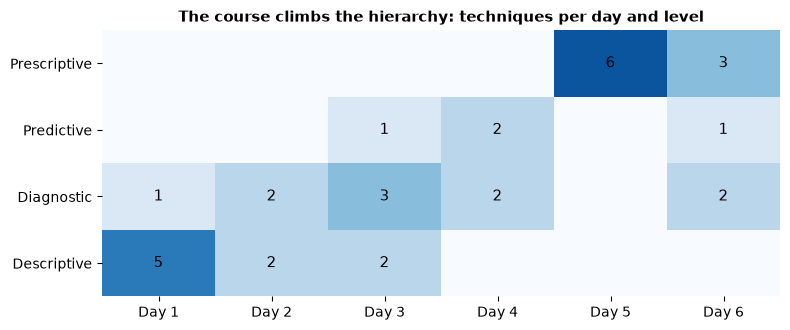

In [3]:
techniques = [
    # (day, technique, level, needs from the level below)
    (1, "Summary statistics, describe()", "Descriptive", "Clean data with known types and units"),
    (1, "Missing values and data-quality checks", "Descriptive", "A clear definition of each field"),
    (1, "Histograms, skew and outliers", "Descriptive", "The right grain (one row = one thing)"),
    (1, "Pivot tables and groupby", "Descriptive", "Sensible groups and a stated measure"),
    (1, "Correlation", "Descriptive", "Paired numeric data, a look at the scatter"),
    (1, "Confounding and Simpson's paradox", "Diagnostic", "A breakdown by the hidden third variable"),
    (2, "Chart choice by question shape", "Descriptive", "A clear question and an honest summary"),
    (2, "KPI dashboards in Tableau", "Descriptive", "One agreed definition per KPI"),
    (2, "Funnel and channel metrics", "Diagnostic", "Counts at each stage, defined consistently"),
    (2, "A/B test", "Diagnostic", "Random assignment and enough visitors"),
    (3, "Word frequency and n-grams", "Descriptive", "Tokenised, normalised text"),
    (3, "VADER sentiment scores", "Descriptive", "Text in the language the lexicon knows"),
    (3, "Checking scores against human labels", "Diagnostic", "A labelled sample"),
    (3, "Decomposition: trend and season", "Diagnostic", "A regular, time-ordered series"),
    (3, "ADF test and differencing", "Diagnostic", "A plot of the series first"),
    (3, "SARIMA forecast with RMSE and MAE", "Predictive", "Stationarity and a time-ordered test set"),
    (4, "Multiple regression for prediction", "Predictive", "Explored data and a train/test split"),
    (4, "Residual plots", "Diagnostic", "A fitted model"),
    (4, "VIF for multicollinearity", "Diagnostic", "The predictors' correlations"),
    (4, "Text score as a feature", "Predictive", "A score that has been validated"),
    (5, "Deterministic spreadsheet model", "Prescriptive", "Stated inputs, separated from formulas"),
    (5, "Sensitivity and tornado chart", "Prescriptive", "A working base case"),
    (5, "What-If Data Tables", "Prescriptive", "A single output cell driven by inputs"),
    (5, "Monte Carlo simulation", "Prescriptive", "Distributions for the uncertain inputs"),
    (5, "Risk measures: percentiles, P(loss)", "Prescriptive", "Many frozen trials"),
    (5, "Decision rule: how much to stock", "Prescriptive", "Costs of too much and too little"),
    (6, "KPI trees and data-quality scorecards", "Diagnostic", "Governed definitions"),
    (6, "Forecast Sheet (ETS) with a bound", "Predictive", "A numeric timeline and enough history"),
    (6, "Planning against an upper bound", "Prescriptive", "A forecast interval and a cost of overrun"),
    (6, "Disparate-impact audit", "Diagnostic", "Outcomes recorded by group"),
    (6, "Multi-criteria scoring with red lines", "Prescriptive", "Agreed weights and constraints"),
    (6, "Managerial recommendation", "Prescriptive", "Evidence from every level below"),
]
levels = ["Descriptive", "Diagnostic", "Predictive", "Prescriptive"]
hier = pd.DataFrame(techniques, columns=["Day", "Technique", "Level", "Needs from below"])
print(hier.to_string(index=False))

counts = pd.crosstab(hier["Level"], hier["Day"]).reindex(levels[::-1])
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.imshow(counts.values, cmap="Blues", aspect="auto", vmin=0, vmax=counts.values.max() + 1)
for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        v = counts.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=11, color="black")
ax.set_xticks(range(counts.shape[1]), [f"Day {d}" for d in counts.columns])
ax.set_yticks(range(len(levels)), counts.index)
ax.set_title("The course climbs the hierarchy: techniques per day and level")
ax.spines[["left", "bottom"]].set_visible(False)
plt.tight_layout()
plt.show()

Read the chart from bottom left to top right: the course climbs. Days 1 and 2 describe; Day 3 starts to explain and to predict; Day 4 predicts; Days 5 and 6 prescribe. The dependency runs **one way**:

- A **diagnostic** claim needs a description to explain. Simpson's paradox (Day 1) only appears after you have the overall and the group-level summaries.
- A **prediction** needs an honest description of the past. The ADF test (Day 3) is only meaningful once you have plotted the series and seen whether it drifts.
- A **prescription** needs a prediction with its uncertainty. A Data Table or a Monte Carlo run (Day 5) varies a base case that someone first had to forecast.

### Three misconceptions

| Misconception | Why it is wrong |
|---|---|
| "Prescriptive is the most advanced, so it is always the best answer." | A prescription built on a careless description is worse than a careful description, because it looks authoritative. Use the lowest level that answers the question. |
| "Descriptive analytics is just the warm-up." | Most business questions are descriptive ("which region fell?"), and most failed models fail because the description was skipped. |
| "A predictive model tells you what to do." | It tells you what is likely if nothing changes. Choosing what to do needs costs, constraints and values, which belong to the prescriptive level and to the people deciding. |

> **Self-check (one sentence each).** Place each of these on the hierarchy and say what it needs from below: a residual plot; a Tableau filter; a word cloud; a probability of loss; a forecast confidence interval.

---

## Part 3: One discipline, six checks (core)

Every modelling day had a check that came **before** you could trust the result. They look unrelated: a p-value from a unit-root test, a ratio from a regression, a grid of profits, a histogram, an interval. Underneath, each one does the same three things:

1. **Name** a condition the technique quietly assumes.
2. **Test** whether this data or this model meets it.
3. **Report** what happens to the answer when the condition is stressed instead of assumed.

A model that skips the check still produces a number. What it cannot tell you is how far to trust that number.

| Check | Technique it protects | The assumption it tests | What goes wrong if you skip it | What to report | Where taught |
|---|---|---|---|---|---|
| **ADF test** (and differencing) | ARIMA and SARIMA forecasts | The series has a stable mean and variance (stationarity) after any differencing | The model treats a random drift as a pattern; two drifting series look related when they are not (a spurious regression) | The test result before and after differencing, and the differencing order used | Day 3, Part 7 |
| **VIF** | Multiple regression | The predictors are not so entangled that their separate effects cannot be told apart | Coefficients swing, change sign or look "insignificant" although the variables matter; a manager is told the wrong lever | VIFs, and whether the model is for **prediction** (tolerable) or **explanation** (act on it) | Day 4, Part 9 |
| **Train and test split** | Any predictive model | Accuracy on the data used for fitting says nothing about new data | Over-fitting: a model that memorises the past and fails on the future; for time series, a random split leaks the future | Error on the **test** set, set against the scale of the outcome | Day 3, Part 3; Day 4, Part 5 |
| **Data Table sweep** | A deterministic spreadsheet model | The base case is representative of the plausible inputs | A comfortable base case hides a region of losses next door; nobody knows which input matters most | The range of outputs, and the input values at which the decision switches | Day 5, Parts 3–5 |
| **Monte Carlo** | A model with several uncertain inputs at once | Average inputs give the average output (they often do not), and the spread does not matter | The flaw of averages; a plan with a large chance of loss looks fine on its mean | Percentiles, the probability of a loss, and the number of trials | Day 5, Parts 6–10 |
| **Confidence bound** | A forecast used for a plan | A point forecast is a safe planning number | A plan set at the point is exceeded about half the time; costly when an overrun hurts more than a surplus | The interval, which bound the plan uses, and why | Day 3, Part 9; Day 6, Parts 6–7 |

Two more checks belong in the same family: the **residual plot** (Day 4, Part 7: is the model's error pattern-free?) and **validating sentiment against human labels** (Day 3, Part 8: does the score measure what we think?).

The six short demonstrations below each show the failure that one check catches. All the data is synthetic.

### A. The ADF test: a drift is not a trend

Two **independent** random walks share nothing: each step of one is unrelated to the other. Regress one on the other, in levels and then in differences.

> **Predict, then run.** Will the regression in levels find a strong relationship between two series that are unrelated by construction?

In [4]:
rng = np.random.default_rng(10)
n = 120
walk_a = 100 + np.cumsum(rng.normal(0, 1, n))     # random walk: today = yesterday + noise
walk_b = 50 + np.cumsum(rng.normal(0, 1, n))      # an independent random walk

for name, series in [("walk A, levels", walk_a), ("walk A, first difference", np.diff(walk_a))]:
    with warnings.catch_warnings():               # newer statsmodels warns about a future return type
        warnings.simplefilter("ignore", FutureWarning)
        stat, pvalue = adfuller(series)[:2]
    print(f"ADF on {name:<26} statistic {stat:6.2f}   p-value {pvalue:.3f}")

r2_levels = sm.OLS(walk_b, sm.add_constant(walk_a)).fit().rsquared
r2_diffs = sm.OLS(np.diff(walk_b), sm.add_constant(np.diff(walk_a))).fit().rsquared
print(f"\nR² of B on A in levels:      {r2_levels:.2f}")
print(f"R² of B on A in differences: {r2_diffs:.2f}")

ADF on walk A, levels             statistic  -1.76   p-value 0.402
ADF on walk A, first difference   statistic  -8.53   p-value 0.000

R² of B on A in levels:      0.89
R² of B on A in differences: 0.00


The ADF test's null hypothesis is **"the series has a unit root" (it is not stationary)**. A large p-value for the levels means we cannot reject a wandering mean; after differencing, the p-value is tiny and the series is stationary. In levels, the two unrelated walks show a large R², because both happen to drift over the same stretch. In differences, the relationship disappears, because there was never one. **What the ADF test protects against:** building a forecast, or a regression, on a drift.

### B. VIF: entangled predictors give unstable coefficients

A rent model with two predictors that move together almost perfectly: floor area and number of rooms. Fit it on two random halves of the same data.

> **Predict, then run.** Both halves come from the same process. Will the two fitted coefficients for floor area be close?

In [5]:
rng = np.random.default_rng(2)
n = 80
area = rng.uniform(40, 120, n)                       # square metres
rooms = area / 25 + rng.normal(0, 0.15, n)           # rooms track area closely
rent = 300 + 9 * area + 60 * rooms + rng.normal(0, 90, n)
flats = pd.DataFrame({"area": area, "rooms": rooms, "rent": rent})

X = sm.add_constant(flats[["area", "rooms"]])
vif = {col: variance_inflation_factor(X.values, i) for i, col in enumerate(X.columns) if col != "const"}
print("VIF:", ", ".join(f"{k} {v:.1f}" for k, v in vif.items()))

half = rng.permutation(n)
for label, idx in [("first half ", half[:40]), ("second half", half[40:])]:
    fit = smf.ols("rent ~ area + rooms", data=flats.iloc[idx]).fit()
    print(f"{label}: area coefficient {fit.params['area']:6.1f}   rooms coefficient {fit.params['rooms']:7.1f}"
          f"   R² {fit.rsquared:.2f}")

VIF: area 43.4, rooms 43.4
first half : area coefficient   13.6   rooms coefficient   -58.0   R² 0.83
second half: area coefficient    6.8   rooms coefficient   138.2   R² 0.89


The VIFs are far above the usual warning level of about 5 to 10, and the two halves disagree about how much each variable is worth (one half even gives rooms a negative effect), even though the R² stays healthy in both. That is the pattern to remember: **multicollinearity hurts explanation, not prediction**. If the model only has to predict rent for flats like these, it may be fine. If a manager asks "how much is one extra room worth?", the coefficients cannot answer. **What VIF protects against:** telling someone the wrong lever.

### C. Train and test: a flexible model can memorise noise

Twenty-four months of a smooth relationship plus noise. Fit a straight line and a flexible curve (a polynomial of degree 4) to the first 16 points, and test both on the last 8.

> **Predict, then run.** Which model will have the smaller error on the training data? Which on the test data?

 degree  train RMSE  test RMSE
      1        1.22       2.83
      4        1.10      37.41


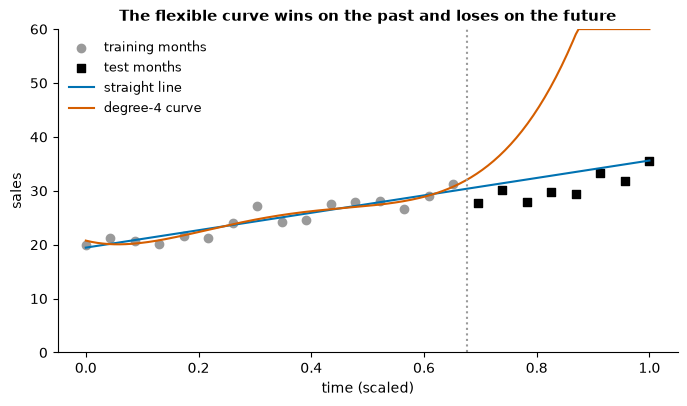

In [6]:
rng = np.random.default_rng(7)
x = np.linspace(0, 1, 24)
y = 20 + 15 * x + rng.normal(0, 2, 24)
train, test = slice(0, 16), slice(16, 24)           # time order: fit on the past, test on the future

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

rows = []
fits = {}
for degree in (1, 4):
    model = np.polynomial.Polynomial.fit(x[train], y[train], degree)
    fits[degree] = model
    rows.append({"degree": degree, "train RMSE": rmse(model(x[train]), y[train]),
                 "test RMSE": rmse(model(x[test]), y[test])})
print(pd.DataFrame(rows).round(2).to_string(index=False))

grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots()
ax.scatter(x[train], y[train], color=GREY, label="training months")
ax.scatter(x[test], y[test], color="black", marker="s", label="test months")
ax.plot(grid, fits[1](grid), color=BLUE, label="straight line")
ax.plot(grid, np.clip(fits[4](grid), 0, 60), color=ORANGE, label="degree-4 curve")
ax.axvline(x[16] - 0.02, color=GREY, linestyle=":")
ax.set_ylim(0, 60)
ax.set_xlabel("time (scaled)")
ax.set_ylabel("sales")
ax.set_title("The flexible curve wins on the past and loses on the future")
ax.legend(frameon=False, fontsize=9)
plt.show()

On the training months the flexible curve wins; on the test months it loses badly, because it bent itself around the noise and then extrapolated that bend into the future. **What the train and test split protects against:** reporting the training error as if it were the error on next month. For time series the split must be **in time order** (Day 3, Part 3); a random split lets the model peek at the future.

### D. The Data Table sweep: the base case hides the cliff

A product line earns a margin per unit on its sales volume and pays a fixed cost. The base case is a margin of $20 on 5,000 units, against fixed costs of $80,000. Sweep both inputs, as a two-way Data Table would (Day 5, Part 4).

> **Predict, then run.** The base case makes a profit. Roughly what share of this plausible grid of inputs makes a loss?

In [7]:
fixed_cost = 80_000
margins = np.array([14, 16, 18, 20, 22, 24, 26])           # $ per unit
volumes = np.array([3500, 4000, 4500, 5000, 5500, 6000, 6500])  # units
grid = pd.DataFrame(np.outer(volumes, margins) - fixed_cost,
                    index=pd.Index(volumes, name="units"), columns=pd.Index(margins, name="margin $"))
print("Profit ($) for each margin (columns) and volume (rows):")
print(grid.to_string())
print(f"\nBase case (margin $20, 5,000 units): {usd(20 * 5000 - fixed_cost)}")
print(f"Share of the grid with a loss: {(grid < 0).to_numpy().mean():.0%}")
print(f"Break-even volume at a $20 margin: {fixed_cost / 20:,.0f} units")

Profit ($) for each margin (columns) and volume (rows):
margin $     14     16     18     20     22     24     26
units                                                    
3500     -31000 -24000 -17000 -10000  -3000   4000  11000
4000     -24000 -16000  -8000      0   8000  16000  24000
4500     -17000  -8000   1000  10000  19000  28000  37000
5000     -10000      0  10000  20000  30000  40000  50000
5500      -3000   8000  19000  30000  41000  52000  63000
6000       4000  16000  28000  40000  52000  64000  76000
6500      11000  24000  37000  50000  63000  76000  89000

Base case (margin $20, 5,000 units): $20,000
Share of the grid with a loss: 24%
Break-even volume at a $20 margin: 4,000 units


The base case looks comfortable, yet a sizeable part of the grid is red, and the cliff starts close to the base case. The sweep also shows **which input matters more** (compare a step along a row with a step down a column) and the **switching values** (the break-even volume for each margin). **What the sweep protects against:** a single number that hides how close the decision is to changing.

### E. Monte Carlo: the average plan is not the average outcome

Same model, but now margin and volume are uncertain at the same time: margin around $20 (standard deviation $3), volume around 5,000 units (standard deviation 900). Draw 10,000 trials.

> **Predict, then run.** The average inputs give a profit of $20,000. Will the average simulated profit be close to that? What chance of a loss do you expect?

Profit at average inputs:  $20,000
Mean simulated profit:     $20,023
5th to 95th percentile:    -$16,469 to $60,513
Probability of a loss:     20.4%


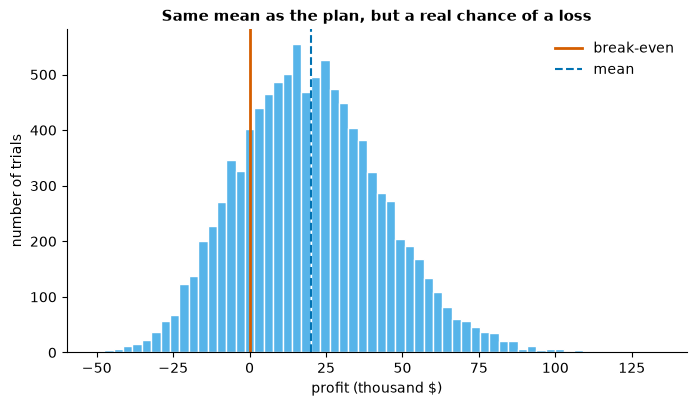

In [8]:
rng = np.random.default_rng(2026)
trials = 10_000
margin = rng.normal(20, 3, trials)
volume = rng.normal(5000, 900, trials)
profit = margin * volume - fixed_cost

print(f"Profit at average inputs:  {usd(20 * 5000 - fixed_cost)}")
print(f"Mean simulated profit:     {usd(profit.mean())}")
print(f"5th to 95th percentile:    {usd(np.percentile(profit, 5))} to {usd(np.percentile(profit, 95))}")
print(f"Probability of a loss:     {(profit < 0).mean():.1%}")

fig, ax = plt.subplots()
ax.hist(profit / 1000, bins=60, color=SKY, edgecolor="white")
ax.axvline(0, color=ORANGE, linewidth=2, label="break-even")
ax.axvline(profit.mean() / 1000, color=BLUE, linestyle="--", label="mean")
ax.set_xlabel("profit (thousand $)")
ax.set_ylabel("number of trials")
ax.set_title("Same mean as the plan, but a real chance of a loss")
ax.legend(frameon=False)
plt.show()

Here the mean is close to the plan because profit is a simple product of independent inputs. With a cap (capacity, stock, a contract limit), the mean of the outputs falls **below** the output of the mean inputs: that is the flaw of averages (Day 5, Part 6), and you will see it in Part 5. Either way, the mean hides the spread: there is a material chance of a loss that the single-number plan never showed. **What Monte Carlo protects against:** planning on one number when several inputs are uncertain together.

### F. Confidence bounds: planning on the point is a coin toss

A forecast says next quarter's demand is 1,000 units, with a forecast standard error of 120 units (assume the errors are roughly normal). How often is each plan exceeded?

> **Predict, then run.** If you plan capacity exactly at the point forecast, how often will demand be higher than your plan?

In [9]:
rng = np.random.default_rng(5)
demand = rng.normal(1000, 120, 100_000)        # many possible quarters consistent with the forecast
plans = {"point forecast": 1000,
         "80% upper bound (z = 1.28)": 1000 + 1.28 * 120,
         "95% upper bound (z = 1.96)": 1000 + 1.96 * 120}
for name, plan in plans.items():
    print(f"Plan at the {name:<28} {plan:7.0f} units   demand exceeds plan in {(demand > plan).mean():5.1%} of quarters")

Plan at the point forecast                  1000 units   demand exceeds plan in 50.1% of quarters
Plan at the 80% upper bound (z = 1.28)      1154 units   demand exceeds plan in 10.1% of quarters
Plan at the 95% upper bound (z = 1.96)      1235 units   demand exceeds plan in  2.5% of quarters


A plan at the point forecast is exceeded about half the time. The upper limit of a **two-sided 95% interval** is the 97.5th percentile, so it is exceeded only about 2.5% of the time (Day 6, Part 7). Which bound to use is a business choice, set by how much an overrun costs compared with a surplus. **What the bound protects against:** treating "most likely" as "safe".

### Error measures need a scale

The same discipline applies to error metrics. An RMSE of 40 units is excellent for a product that sells 4,000 a month and useless for one that sells 50. Always report an error **next to the scale of what it measures**: the mean of the outcome, a naive forecast's error, or a percentage. An R² alone is not evidence of a good model either: Part 3B had a healthy R² with untrustworthy coefficients, and Part 3C's flexible curve had an excellent training fit.

---

## Part 4: Integrated case, step 1: from text to a model (core)

### The case

**Kestrel Bikes** rents electric bikes by monthly subscription. A year-long pilot in its home city went well enough that the board is ready to launch in a second city. The open question is **how big a fleet to lease there: 250 bikes or 400?** A bigger fleet can serve more riders, but every leased bike costs money whether anyone rides it or not.

Two sources of evidence are on the table:

- **Pilot data (structured and unstructured).** 80 pilot riders wrote a short comment after their first month, and Kestrel knows whether each one **renewed** at the six-month mark.
- **New-city test rides (unstructured only).** At a weekend test-ride event in the new city, 40 people tried a bike and left a comment. Nobody there has subscribed yet.

The chain we will follow is the one the capstone asks you to follow with different data and a different question: **text → model → simulation → chart → recommendation**. At each hand-over we stop and ask what could break.

| Step | Question | Tool in this notebook | How you would do it in the capstone's tools |
|---|---|---|---|
| Text | What do riders say, as a number? | VADER compound scores | Python (JupyterLab) |
| Model | How does that number relate to renewal? | Renewal rate by sentiment band; logistic regression | Excel `AVERAGEIFS` for the band table |
| Simulation | What profit range does each fleet size give? | numpy Monte Carlo and a sweep | Excel `RAND()`, `NORM.INV`, Data Tables |
| Chart | What does the board need to see? | matplotlib fan chart | Tableau: dimension on Columns, Measure Values on Rows |
| Recommendation | Which fleet, and on what condition? | A short memo | Word, as a PDF |

### Score the pilot comments

Each comment below was written for this lecture from three banks of phrases (positive, mixed and negative), chosen according to an invisible "satisfaction" for each rider; renewal was then drawn from that same satisfaction. So we know the truth, and we can see whether VADER recovers it.

In [10]:
POSITIVE = ["Love the bike, the commute is so much easier now.",
            "Great service and the battery easily lasts all week.",
            "Really happy with it, I cycle to work every day now.",
            "The app works well and swapping a battery takes a minute.",
            "Excellent value compared with taxis. Highly recommend.",
            "Friendly repair team and the bike feels solid.",
            "Brilliant for hills, I arrive at work without sweating.",
            "Smooth ride and the booking is simple."]
MIXED = ["Good bike, but the app crashes when I try to book a repair.",
         "The ride is fine, but the monthly fee feels high.",
         "Nice bike, although the battery drains fast in the cold.",
         "Okay overall. The seat is uncomfortable on long trips.",
         "Useful, but the docking station is often full.",
         "Decent bike, but the lock is awkward to use."]
NEGATIVE = ["The bike broke twice in the first month. Very disappointed.",
            "Terrible support, I waited a week for a repair.",
            "Too expensive for what you get, and the brakes squeal.",
            "The battery died halfway home. Not worth it.",
            "Frustrating app and nobody answers the phone.",
            "The bike was stolen from the dock and the process was awful."]


def write_comment(satisfaction, rng):
    """Pick a phrase bank from the rider's satisfaction, then a phrase at random."""
    if satisfaction > 0.45:
        tier, bank = "positive", POSITIVE
    elif satisfaction > -0.45:
        tier, bank = "mixed", MIXED
    else:
        tier, bank = "negative", NEGATIVE
    return tier, bank[rng.integers(len(bank))]


rng = np.random.default_rng(719)
satisfaction = rng.normal(0, 1, 80)
written = [write_comment(s, rng) for s in satisfaction]
p_renew_true = 1 / (1 + np.exp(-(0.3 + 1.5 * satisfaction)))
pilot = pd.DataFrame({"rider": range(1, 81),
                      "written_as": [w[0] for w in written],
                      "comment": [w[1] for w in written],
                      "renewed": (rng.random(80) < p_renew_true).astype(int)})


def band(score):
    """VADER's usual thresholds."""
    return "Positive" if score >= 0.05 else ("Negative" if score <= -0.05 else "Neutral")


pilot["compound"] = pilot["comment"].apply(lambda t: sia.polarity_scores(t)["compound"])
pilot["band"] = pilot["compound"].apply(band)
print(pilot[["rider", "comment", "compound", "band", "renewed"]].head(8).to_string(index=False))
print(f"\nPilot riders: {len(pilot)}   renewed: {pilot['renewed'].mean():.0%}")

 rider                                                     comment  compound     band  renewed
     1      Excellent value compared with taxis. Highly recommend.    0.8357 Positive        1
     2                      Smooth ride and the booking is simple.    0.0000  Neutral        1
     3        Great service and the battery easily lasts all week.    0.7579 Positive        1
     4           The ride is fine, but the monthly fee feels high.    0.1027 Positive        0
     5      Okay overall. The seat is uncomfortable on long trips.   -0.1779 Negative        0
     6 The bike broke twice in the first month. Very disappointed.   -0.7346 Negative        0
     7             Terrible support, I waited a week for a repair.   -0.1027 Negative        0
     8           Love the bike, the commute is so much easier now.    0.8062 Positive        1

Pilot riders: 80   renewed: 51%


### Validate the score before you use it

Chapter 8's warning is that a number made from text deserves the same scrutiny as any other engineered feature. We have the writers' intended tone, so we can check VADER against it (Day 3, Part 8).

> **Predict, then run.** Will every comment written as negative get a negative VADER score?

In [11]:
check = pd.crosstab(pilot["written_as"], pilot["band"]).reindex(
    index=["positive", "mixed", "negative"], columns=["Positive", "Neutral", "Negative"], fill_value=0)
print("Intended tone (rows) against VADER's band (columns):")
print(check.to_string())

phrases = pd.DataFrame([(tier, t, sia.polarity_scores(t)["compound"])
                        for tier, bank in [("positive", POSITIVE), ("mixed", MIXED), ("negative", NEGATIVE)]
                        for t in bank], columns=["written_as", "phrase", "compound"])
misreads = phrases[((phrases["written_as"] == "positive") & (phrases["compound"] < 0.05)) |
                   ((phrases["written_as"] == "negative") & (phrases["compound"] > -0.05))]
print("\nPhrases VADER misreads:")
print(misreads.to_string(index=False))

Intended tone (rows) against VADER's band (columns):
band        Positive  Neutral  Negative
written_as                             
positive          24        3         0
mixed             17        0         9
negative           0        3        24

Phrases VADER misreads:
written_as                                                 phrase  compound
  positive                 Smooth ride and the booking is simple.       0.0
  negative Too expensive for what you get, and the brakes squeal.       0.0


Most comments written as clearly positive or clearly negative land in the right band, and the mixed comments split both ways, as you would expect from "good, but" sentences. Not every comment lands well, though. "Smooth ride and the booking is simple" is praise for a bike, but none of its words are in VADER's general-purpose lexicon, so it scores zero. "Too expensive for what you get, and the brakes squeal" is a complaint, but "expensive" and "squeal" carry no score either. Domain words (price, brakes, ride quality) are exactly where a lexicon built for social media goes blind. In a report you would **say so**, give an example, and treat the score as a noisy measure.

### Model: from a sentiment score to a renewal rate

Two models, one simple enough for a spreadsheet and one smoother:

1. **Band table.** The renewal rate within each VADER band. In Excel: `=AVERAGEIFS(renewed_range, band_range, "Positive")`.
2. **Logistic regression** of renewal on the compound score (Day 4, Part 13): it gives a renewal probability for any score between −1 and 1.

> **Predict, then run.** How much higher do you expect the renewal rate of Positive riders to be than that of Negative riders?

In [12]:
band_table = (pilot.groupby("band")["renewed"].agg(riders="count", renewal_rate="mean")
              .reindex(["Positive", "Neutral", "Negative"]))
print(band_table.round(2).to_string())

logit = smf.logit("renewed ~ compound", data=pilot).fit(disp=0)
print(f"\nLogistic regression: intercept {logit.params['Intercept']:.2f}, "
      f"slope {logit.params['compound']:.2f} (standard error {logit.bse['compound']:.2f})")
for score in (-0.6, 0.0, 0.6):
    p = logit.predict(pd.DataFrame({"compound": [score]}))[0]
    print(f"  predicted renewal at a compound score of {score:+.1f}: {p:.0%}")

          riders  renewal_rate
band                          
Positive      41          0.66
Neutral        6          0.50
Negative      33          0.33

Logistic regression: intercept -0.10, slope 1.90 (standard error 0.57)
  predicted renewal at a compound score of -0.6: 22%
  predicted renewal at a compound score of +0.0: 48%
  predicted renewal at a compound score of +0.6: 74%


The relationship is real but loose: sentiment moves renewal by tens of percentage points, not from zero to one, and the slope's standard error is large because 80 riders is a small sample. Note also the **Neutral** row: it is built from very few riders, so its rate is little more than noise. This is the hand-over from text to model, and its weak seam is double: a **noisy score** (misreads) feeding a **small sample**.

---

## Part 5: Integrated case, step 2: from a model to a simulation (core)

### Apply the model to the new city

Score the 40 test-ride comments, then predict a renewal rate for the new city in two ways: from the logistic model (average the predicted probabilities) and from the band table (weight each band's rate by its share of comments).

In [13]:
rng = np.random.default_rng(1119)
city_satisfaction = rng.normal(0.5, 1, 40)          # the event attracted keener people (see below)
city = pd.DataFrame({"comment": [write_comment(s, rng)[1] for s in city_satisfaction]})
city["compound"] = city["comment"].apply(lambda t: sia.polarity_scores(t)["compound"])
city["band"] = city["compound"].apply(band)

renewal_logit = logit.predict(city).mean()
shares = city["band"].value_counts(normalize=True).reindex(band_table.index, fill_value=0)
renewal_bands = (shares * band_table["renewal_rate"]).sum()
renewal_pilot = pilot["renewed"].mean()

print(f"Mean compound score: pilot {pilot['compound'].mean():+.2f}, new-city test rides {city['compound'].mean():+.2f}")
print(f"Band shares in the new city: " + ", ".join(f"{b} {s:.0%}" for b, s in shares.items()))
print(f"\nPredicted six-month renewal, logistic model: {renewal_logit:.1%}")
print(f"Predicted six-month renewal, band table:     {renewal_bands:.1%}")
print(f"Actual six-month renewal in the pilot city:  {renewal_pilot:.1%}")

Mean compound score: pilot +0.08, new-city test rides +0.21
Band shares in the new city: Positive 68%, Neutral 2%, Negative 30%

Predicted six-month renewal, logistic model: 56.8%
Predicted six-month renewal, band table:     55.7%
Actual six-month renewal in the pilot city:  51.2%


The new city's comments are more positive, so both models predict a **higher** renewal rate than the pilot achieved. Should we believe it? Think about **who wrote the comments**. Pilot riders were paying customers a month into their subscription. Test-ride visitors chose to come to a weekend event and rode a new bike for twenty minutes; they are keener than the average future subscriber, and a short ride shows none of the battery, repair and docking problems that drive the pilot's complaints. This is **selection bias**, and it is the second weak seam: the model is fine, but the input is not drawn from the population we want to predict.

A defensible analyst does not pick one number. She carries a **range** forward: the pilot's actual rate as a cautious case, the model's prediction as an optimistic case, and lets the simulation show whether the decision depends on which is true.

### The simulation

The monthly business model, with every input stated (all invented):

| Input | Value | Uncertain? |
|---|---|---|
| Subscription price | $69 per rider per month | No |
| Variable cost (insurance, batteries, repairs) | $15 per rider per month | No |
| Lease cost | $20 per bike per month, for every bike leased | No |
| Fixed cost (depot, staff) | $5,000 per month | No |
| Launch cost | $25,000 once | No |
| New sign-ups per month | Poisson, with a monthly average drawn once per trial from Normal(45, 12) | **Yes** |
| Six-month renewal rate | Normal around the central estimate, standard deviation 7 points | **Yes** |
| Capacity | Active riders can never exceed the fleet | Fixed by the decision |

A six-month renewal rate *R* is turned into a monthly retention rate *R*<sup>1/6</sup>, so that six months of retention multiply back to *R*. Each month, active riders = retained riders + new sign-ups, capped at the fleet size. Profit is summed over 24 months.

> **Predict, then run.** Which fleet has the higher average 24-month profit? Which has the higher chance of a loss? Are those the same fleet?

In [14]:
PRICE, VAR_COST, LEASE, FIXED, LAUNCH, MONTHS = 69, 15, 20, 5_000, 25_000, 24


def simulate(fleet, renewal_mean, renewal_sd=0.07, signups_mean=45, signups_sd=12, trials=5_000, seed=2026):
    """Return cumulative profit by month (months x trials) for one fleet size."""
    g = np.random.default_rng(seed)                  # same seed for both fleets: a fair comparison
    renewal = np.clip(g.normal(renewal_mean, renewal_sd, trials), 0.2, 0.97)
    retention = renewal ** (1 / 6)
    signup_rate = np.clip(g.normal(signups_mean, signups_sd, trials), 5, None)
    active = np.zeros(trials)
    cumulative = np.full(trials, -float(LAUNCH))
    path = np.empty((MONTHS, trials))
    for month in range(MONTHS):
        active = np.minimum(np.round(active * retention) + g.poisson(signup_rate), fleet)
        cumulative = cumulative + (PRICE - VAR_COST) * active - LEASE * fleet - FIXED
        path[month] = cumulative
    return path


def summarise(final):
    return {"mean": final.mean(), "5th pct": np.percentile(final, 5), "median": np.median(final),
            "95th pct": np.percentile(final, 95), "P(loss)": (final < 0).mean()}


central = (renewal_pilot + renewal_logit) / 2       # midway between the cautious and optimistic cases
paths = {fleet: simulate(fleet, central) for fleet in (250, 400)}
summary = pd.DataFrame({f"{fleet} bikes": summarise(p[-1]) for fleet, p in paths.items()}).T
print(f"Central six-month renewal used: {central:.1%}\n")
print(summary.assign(**{c: summary[c].map(usd) for c in ["mean", "5th pct", "median", "95th pct"]},
                     **{"P(loss)": summary["P(loss)"].map("{:.0%}".format)}).to_string())

Central six-month renewal used: 54.0%

              mean    5th pct   median  95th pct P(loss)
250 bikes  $10,829   -$54,459  $20,660   $37,025     21%
400 bikes  $21,656  -$126,459  $43,403  $110,015     33%


The larger fleet has the higher **average** profit and also the higher **chance of a loss** and the worse bad case. That is the normal shape of a capacity decision: the big fleet earns more when demand is strong, and leaves more bikes idle, still costing lease, when it is weak. Neither number alone settles the question; which matters more depends on how much loss Kestrel can absorb.

Notice also the flaw of averages from Part 3E at work: because riders are capped at the fleet size, a good month cannot make up fully for a bad one.

### Sweep the uncertain assumption

The renewal rate is the assumption we trust least, so sweep it, as a one-way Data Table would, holding everything else at its central value. Where does the decision switch?

Mean 24-month profit by renewal rate:
                  250 bikes 400 bikes
six-month renewal                    
0.35               -$13,438  -$53,844
0.40                -$4,659  -$31,904
0.45                 $2,121  -$11,336
0.50                 $7,225    $7,118
0.55                $11,047   $23,197
0.60                $13,944   $36,751
0.65                $16,228   $47,934
0.70                $18,026   $57,043
0.75                $19,495   $64,419

The larger fleet first wins on average at a renewal rate of about 51% (pilot actual 51%, test-ride prediction 57%).


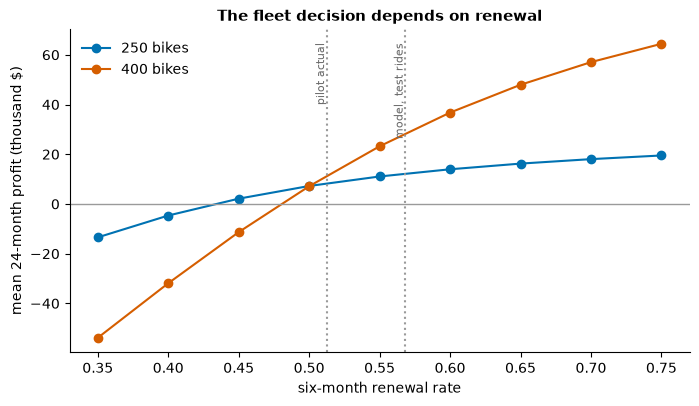

In [15]:
renewal_grid = np.round(np.arange(0.35, 0.751, 0.05), 2)
sweep = pd.DataFrame({f"{fleet} bikes": [simulate(fleet, r, trials=2_000)[-1].mean() for r in renewal_grid]
                      for fleet in (250, 400)}, index=pd.Index(renewal_grid, name="six-month renewal"))
print("Mean 24-month profit by renewal rate:")
print(sweep.map(usd).to_string())

fine_grid = np.round(np.arange(0.40, 0.651, 0.01), 2)      # a finer sweep to locate the switch
gap = np.array([simulate(400, r, trials=2_000)[-1].mean() - simulate(250, r, trials=2_000)[-1].mean()
                for r in fine_grid])
switch = fine_grid[np.argmax(gap > 0)]
print(f"\nThe larger fleet first wins on average at a renewal rate of about {switch:.0%} "
      f"(pilot actual {renewal_pilot:.0%}, test-ride prediction {renewal_logit:.0%}).")

fig, ax = plt.subplots()
ax.plot(renewal_grid, sweep["250 bikes"] / 1000, marker="o", color=BLUE, label="250 bikes")
ax.plot(renewal_grid, sweep["400 bikes"] / 1000, marker="o", color=ORANGE, label="400 bikes")
ax.axhline(0, color=GREY, linewidth=1)
for value, label in [(renewal_pilot, "pilot actual"), (renewal_logit, "model, test rides")]:
    ax.axvline(value, color=GREY, linestyle=":")
    ax.text(value, ax.get_ylim()[1] * 0.92, label, rotation=90, va="top", ha="right", fontsize=8, color="dimgray")
ax.set_xlabel("six-month renewal rate")
ax.set_ylabel("mean 24-month profit (thousand $)")
ax.set_title("The fleet decision depends on renewal")
ax.legend(frameon=False)
plt.show()

The sweep turns an argument about adjectives ("renewal will be good") into a question with a number in it: **is renewal in the new city above or below the switching value?** The pilot's actual rate sits almost on the switching value; only the optimistic test-ride prediction is clearly above it. Below the switch the larger fleet loses money fast, while above it the gain grows more slowly. So the honest answer is that the evidence does not yet settle the fleet size, and the recommendation should be built around that fact rather than hiding it.

---

## Part 6: Integrated case, step 3: from a simulation to a chart and a recommendation (core)

### The chart for the board

A board member has thirty seconds. The chart must show the two options, over time, **with their range**, not just a central line (Chapter 8's point about carrying the honest range forward). A fan chart does that: the median path and a band from the 5th to the 95th percentile.

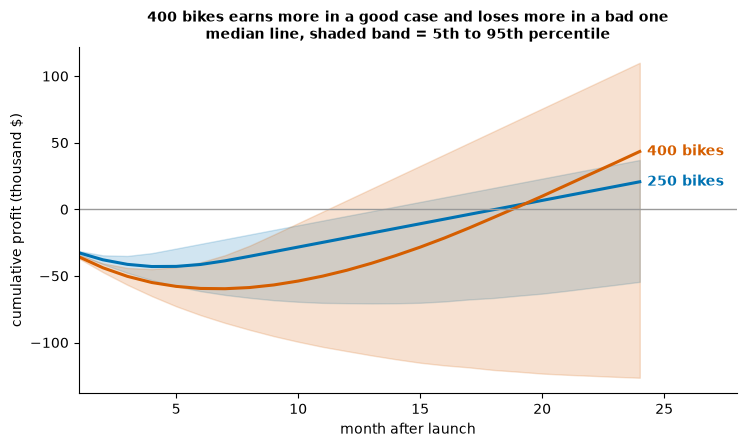

In [16]:
months = np.arange(1, MONTHS + 1)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for fleet, colour in [(250, BLUE), (400, ORANGE)]:
    p = paths[fleet] / 1000
    ax.fill_between(months, np.percentile(p, 5, axis=1), np.percentile(p, 95, axis=1), color=colour, alpha=0.18)
    ax.plot(months, np.median(p, axis=1), color=colour, linewidth=2.2)
    ax.text(MONTHS + 0.3, np.median(p[-1]), f"{fleet} bikes", color=colour, va="center", fontweight="bold")
ax.axhline(0, color=GREY, linewidth=1)
ax.set_xlim(1, MONTHS + 4)
ax.set_xlabel("month after launch")
ax.set_ylabel("cumulative profit (thousand $)")
ax.set_title("400 bikes earns more in a good case and loses more in a bad one\n"
             "median line, shaded band = 5th to 95th percentile", fontsize=10)
plt.show()

Choices worth copying: a **message title** that states the finding; **direct labels** instead of a legend; a **zero line**, because "do we lose money?" is the board's first question; colour-blind-safe colours; the **range** shaded.

**The same chart in Tableau** (the tool the capstone uses for its chart). Export a table with one row per month and columns for each option's 5th percentile, median and 95th percentile. Then:

1. Put **Month** on Columns and make sure it is a **dimension** (or a continuous dimension), not `SUM(Month)`.
2. Put **Measure Values** on Rows, and keep only the measures you want on the **Measure Values** card.
3. Put **Measure Names** on Color, choose **Line** marks, and format the axis as **currency**.
4. For the band, use two median lines and add a **reference band** between the percentile measures, or show the percentiles as thin lines.

### The recommendation

Day 6, Part 14 gave the structure: **answer first**, then the evidence, the trade-off in plain units, the conditions, and the decision requested. Label each statement as a **fact** (measured), an **estimate** (modelled) or a **judgement** (yours). The memo below is generated from the numbers above, so it stays consistent with them.

In [17]:
s250, s400 = summary.loc["250 bikes"], summary.loc["400 bikes"]
memo = f"""
TO: Kestrel Bikes board           FROM: BI team           RE: Fleet size for the second city

RECOMMENDATION. Launch with 250 bikes, with a pre-agreed option to lease 150 more once the first
six-month renewal rate in the new city is known. Add them if renewal is at or above about {switch:.0%}.

EVIDENCE.
 - [Fact] In the pilot, {renewal_pilot:.0%} of riders renewed at six months; riders whose comments scored
   Positive renewed at {band_table.loc['Positive', 'renewal_rate']:.0%} and those scored Negative at {band_table.loc['Negative', 'renewal_rate']:.0%}.
 - [Estimate] Test-ride comments predict a renewal rate of {renewal_logit:.0%}, but test riders are keener
   than paying subscribers, so we treat this as an optimistic case.
 - [Estimate] Over 24 months, 400 bikes averages {usd(s400['mean'])} against {usd(s250['mean'])} for 250 bikes,
   but its chance of a loss is {s400['P(loss)']:.0%} against {s250['P(loss)']:.0%}, and its bad case (5th percentile)
   is {usd(s400['5th pct'])} against {usd(s250['5th pct'])}.

TRADE-OFF. The larger fleet buys about {usd(s400['mean'] - s250['mean'])} of extra average profit at the cost of a
deeper bad case. Which fleet wins depends on renewal, which the evidence cannot yet pin down.

CONDITIONS. [Judgement] The staged plan is right if the extra bikes can be leased within about two
months and the lease allows it. If the lessor offers only one fleet size, the board must choose
between the higher average and the safer downside, and should say which it values.

LIMITS. Sentiment scores misread domain words such as price and brakes; the pilot sample is 80 riders;
all costs are budget estimates. Comments were analysed in aggregate and no rider is identified.

DECISION REQUESTED. Approve a 250-bike launch and negotiate the expansion option now.
"""
print(memo)


TO: Kestrel Bikes board           FROM: BI team           RE: Fleet size for the second city

RECOMMENDATION. Launch with 250 bikes, with a pre-agreed option to lease 150 more once the first
six-month renewal rate in the new city is known. Add them if renewal is at or above about 51%.

EVIDENCE.
 - [Fact] In the pilot, 51% of riders renewed at six months; riders whose comments scored
   Positive renewed at 66% and those scored Negative at 33%.
 - [Estimate] Test-ride comments predict a renewal rate of 57%, but test riders are keener
   than paying subscribers, so we treat this as an optimistic case.
 - [Estimate] Over 24 months, 400 bikes averages $21,656 against $10,829 for 250 bikes,
   but its chance of a loss is 33% against 21%, and its bad case (5th percentile)
   is -$126,459 against -$54,459.

TRADE-OFF. The larger fleet buys about $10,827 of extra average profit at the cost of a
deeper bad case. Which fleet wins depends on renewal, which the evidence cannot yet pin down.

COND

Three things make this memo defensible rather than merely confident:

- **It carries the range.** The average, the bad case and the probability of a loss all appear, and the trade-off between them is stated in dollars.
- **It names the seams.** The misread domain words and the selection bias are stated as limits, not hidden.
- **It turns uncertainty into an action.** Instead of guessing renewal, the recommendation buys the information (six months of real renewals) before committing to the larger fleet. When the evidence cannot settle a decision, a staged decision with a clear trigger is often the best prescriptive answer.

### What each hand-over needed

| Hand-over | What could break | The check that catches it |
|---|---|---|
| Text → score | The lexicon misreads domain words | Validate against labelled or hand-read examples (Day 3, Part 8) |
| Score → model | Small sample; a loose, noisy relationship | Look at counts per band and the slope's standard error; test on held-out riders if there are enough |
| Model → new city | The new inputs come from a different population (selection bias) | Ask who wrote the text and why; carry a range, not a point |
| Model → simulation | One "expected" input hides the spread | Monte Carlo with the uncertain inputs; a sweep of the least trusted one |
| Simulation → chart | A single line implies certainty | Show the band or the percentiles; zero line; message title |
| Chart → recommendation | The answer ignores the downside or the ethics | Fact, estimate, judgement; conditions; limits; the decision requested |

---

## Part 7: Business case discussion: Kestrel's board (self-study, discussion)

Work in groups of three: one analyst, one finance director, one head of operations. The finance director is worried about the downside; the head of operations wants enough bikes to avoid turning riders away.

1. The finance director says: "Your model is built on 80 comments and a sentiment score that cannot read the word *expensive*. Why should I trust any of it?" Answer in three sentences, without claiming more than the evidence shows.
2. The head of operations says: "If we start with 250 bikes and demand is strong, we will turn riders away and they will go to a competitor." Is that a cost the simulation includes? How would you add it?
3. Which of the inputs in the Part 5 table would you most like to measure better before launch, and how would you measure it cheaply?
4. The marketing team proposes to quote the most positive test-ride comments in the launch campaign. What permission and privacy questions does that raise (Day 6, Part 8)?
5. A board member asks for "just one number". Which single number would you give, and what sentence would you always put next to it?
6. Suppose six months later renewal in the new city is exactly at the switching value. What would you recommend then, and why?

---

## Part 8: Common errors by topic (core scan, self-study detail)

These are the mistakes that cost the most marks and the most money. Scan the table in class; read the detail before the capstone.

### Python and data exploration (Days 0 and 1)

| Error | Why it matters | Fix |
|---|---|---|
| Running cells out of order, so a variable holds an old value | Results you cannot reproduce | **Restart and run all** before exporting |
| Reading a mean without checking skew or outliers | A few large values move the mean; the "typical" case is misdescribed | Report the median too; look at the histogram |
| Treating missing values as zeros | Totals and means are biased | Count missing values first; decide and state how you handle them |
| Calling a correlation a cause | Confounders and reverse causation | Say "is associated with"; look for the third variable (Simpson's paradox) |

### Charts and Tableau (Day 2)

| Error | Why it matters | Fix |
|---|---|---|
| Bar chart with a truncated axis | Small differences look huge | Bars start at zero |
| A date or year field left as a **measure** | Tableau adds the years together into one mark | Make it a **dimension** (or a date) |
| Too many measures on **Measure Values** | Unrelated lines on one axis | Keep only the measures you mean to compare |
| A title that names the chart instead of the finding | The reader has to work out the message | Write a message title |
| Colour as the only way to tell series apart | Unreadable for colour-blind readers and in greyscale print | Direct labels, colour-blind-safe palette |

### Text mining (Days 3 and 4)

| Error | Why it matters | Fix |
|---|---|---|
| Removing "not" with the stop words | "not good" becomes "good" | Keep negations for sentiment |
| Trusting VADER on domain language | "Expensive", "sick", "unpredictable plot" are read wrongly or not at all | Validate on a hand-labelled sample |
| Averaging scores from a handful of texts as if they were a survey | Five comments are anecdotes, not a population | Report the count; treat the average as a weak signal |
| A silent fallback scorer | Code that quietly uses a different scorer when a download fails gives different numbers with no warning | Print which scorer ran |

### Forecasting (Days 3 and 6)

| Error | Why it matters | Fix |
|---|---|---|
| Random train/test split on a time series | The model sees the future; the error looks too good | Split in time order |
| Reading a small ADF p-value as "not stationary" | The null hypothesis is *non*-stationarity | Small p-value: reject the unit root, the series is stationary |
| Reporting RMSE without a scale | Nobody can tell whether it is good | Compare with the mean, a naive forecast, or as a percentage |
| Text labels as a timeline in Excel Forecast Sheet | Excel needs numbers or dates | Use a period number or a real date |

### Regression (Day 4)

| Error | Why it matters | Fix |
|---|---|---|
| Judging the model by training R² | Over-fitting goes unnoticed | Report test-set error |
| Reading a coefficient "holding others constant" when VIFs are high | The separate effects cannot be told apart | Say so; drop or combine predictors if you need explanation |
| Predicting far outside the data's range | The fitted line has no evidence there | State the range; refuse or flag extrapolations |
| Forgetting the reference category of a dummy variable | The coefficient is misread | Say "relative to …" |

### Spreadsheets and simulation (Days 5 and 6)

| Error | Why it matters | Fix |
|---|---|---|
| Typing numbers inside formulas | Changing an assumption means hunting through cells | Put every input in its own labelled cell |
| A Data Table whose input cells are on another sheet | Excel refuses | Keep the input cells on the table's sheet |
| Writing about a simulation that has not been frozen | The numbers change when the file reopens | Paste Special → Values first |
| Reporting only the mean of a simulation | The flaw of averages; the risk is hidden | Report percentiles and the probability of a loss |
| Planning on the point forecast when an overrun is costly | Exceeded about half the time | Choose a bound by the cost of being wrong |

### BI, ethics and reports (Days 6 and 7)

| Error | Why it matters | Fix |
|---|---|---|
| Recommending without stating the trade-off | The board cannot see what it gives up | State the cost of the choice in plain units |
| Treating an ethical issue as "a soft factor" with no evidence | It is dismissed | Describe it concretely; price what you can; treat red lines as constraints |
| Mixing facts, estimates and judgements | Readers cannot tell what is measured | Label them, or make it clear in the wording |
| A chart in the report that is not discussed | The evidence is not used | Every chart gets a sentence that says what it shows |

---

## Part 9: Exam technique (core)

The final exam is in periods 3 and 4 today. Your facilitator confirms the format, the length and what you may bring (for example, whether a basic calculator is allowed). Whatever the format, the habits below earn marks.

### Read the command word

| Command word | What it asks for | A weak answer | A strong answer |
|---|---|---|---|
| **Define** | The meaning, precisely | An example only | One-sentence definition, then an example |
| **Describe** | What it is or what happens | Opinion | Features or steps, in order |
| **Explain** | Why or how | A restated description | A cause or mechanism, with "because" |
| **Calculate** | A number, with working | The number alone | Formula, substitution, result with units |
| **Interpret** | What a result means in context | "It is 0.62" | "62% of …, which means … for the manager" |
| **Compare** | Similarities **and** differences | Two separate descriptions | Point-by-point, with a conclusion |
| **Evaluate** | A judgement on strengths and limits | One side only | Both sides, then a reasoned verdict |
| **Recommend** | A decision with justification | A list of options | One option, the evidence, the trade-off and a condition |

### Budget your time

- Before you start, divide the time by the marks: in a 90-minute paper worth 100 marks, a 10-mark question deserves about 9 minutes.
- Answer the questions you are surest of first, but number them clearly.
- Leave five minutes at the end to check units, signs and that every part of every question has an answer.

### Lay out a calculation

1. Write the formula in words or symbols.
2. Substitute the numbers, with units.
3. Give the result, rounded sensibly, with units.
4. Add one sentence saying what it means.

Even if the arithmetic slips, steps 1, 2 and 4 usually earn marks.

### Interpret a number for a manager

Use the pattern **number + unit + context + so what + caveat**. For example: "The test RMSE is 40 units, about 3% of average monthly sales, so the forecast is precise enough for stock planning; it was tested on only eight months, so we will re-check it after the next quarter."

### Read a statistical output

- Find **what was measured** first (the outcome, the units, the sample) before the numbers.
- For a test, write down the **null hypothesis** before reading the p-value (the ADF trap in Part 8).
- For a model, ask **on which data** the metric was computed: training or test.

### Rehearse out loud

Chapter 8's advice is to prepare by speaking, not by memorising. For each chapter, say three things in under a minute, without notes: **what the technique does**, in plain words; **what it assumes or where it fails**; and **one link to a technique from another chapter**. Then ask a friend to interrupt with "why does that matter?" and "what if that assumption fails?". The link is what turns a correct answer into a good one.

---

## Part 10: Practice set (self-study)

Twelve questions written for this page, in the style of a closed-book paper. They are **not** taken from any exam and the exam does not reuse them. No answers are given here: work them alone, then compare with a classmate and with the lecture parts named in brackets. Allow about 60 minutes.

**Q1. Hierarchy (5 marks).** A café chain uses: (a) a dashboard of daily sales by branch; (b) a regression of sales on temperature to set tomorrow's milk order; (c) a breakdown showing that the sales drop came from one branch's closure; (d) a simulation of three opening-hours plans. Place each on the analytics hierarchy and say what each needs from the level below. *(Part 2)*

**Q2. Stationarity (6 marks).** An ADF test on 60 months of a shop's sales gives a p-value of 0.41. After first differencing, the p-value is 0.002. State the null hypothesis, interpret both results, and say what this means for the *d* in an ARIMA(*p*, *d*, *q*) model. *(Part 3A; Day 3, Part 7)*

**Q3. Error and scale (6 marks).** Two forecasts were tested on the last 12 months. Product A: RMSE 35 units, average monthly sales 1,750 units. Product B: RMSE 35 units, average monthly sales 140 units. Express each error as a percentage of average sales and say which forecast you would trust for ordering stock, and why. *(Part 3)*

**Q4. Multicollinearity (6 marks).** A delivery-time model uses distance (km) and fuel used (litres) as predictors. Both VIFs are about 14; the test R² is 0.83. A manager asks how many minutes one extra kilometre adds. What do you tell her, and what would you change if that question is the main purpose of the model? *(Part 3B; Day 4, Part 9)*

**Q5. Over-fitting (5 marks).** A model has a training R² of 0.96 and a test R² of 0.38. Diagnose the problem in one sentence and give two ways to address it. *(Part 3C; Day 4, Part 10)*

**Q6. Sentiment (6 marks).** VADER gives these compound scores: "The delivery was not bad at all" +0.43; "This charger is sick" −0.51; "Arrived on Tuesday" 0.00. Label each with the usual thresholds (±0.05). Which label would a human disagree with, and why does VADER make that mistake? *(Day 3, Parts 6 and 7)*

**Q7. Data Table (6 marks).** A two-way Data Table of monthly profit ($) has prices $8, $9 and $10 across the top and volumes 2,000, 2,500 and 3,000 down the side:

| volume \ price | $8 | $9 | $10 |
|---|---|---|---|
| 2,000 | −6,000 | −4,000 | −2,000 |
| 2,500 | −3,500 | −1,000 | 1,500 |
| 3,000 | −1,000 | 2,000 | 5,000 |

Describe which combinations make a loss, which input the profit is more sensitive to over the ranges shown, and what further information the manager needs before choosing a price. *(Part 3D; Day 5, Part 4)*

**Q8. Monte Carlo (6 marks).** Option X: 2,000 trials, mean profit $52,000, 5th percentile −$30,000, 360 trials below zero. Option Y: mean profit $44,000, 5th percentile $6,000, probability of a loss 2%. Calculate X's probability of a loss. Which option would you recommend to a small firm with little cash, and which to a large firm running many such projects? Explain the difference. *(Part 3E; Day 5, Part 10)*

**Q9. Forecast bounds (5 marks).** Next quarter's demand forecast is 3,200 units, with a 95% interval of 2,700 to 3,700. Renting extra warehouse space at short notice costs four times as much as an unused booked space. Which number would you plan on, and why? *(Part 3F; Day 6, Part 7)*

**Q10. Chart critique (5 marks).** A slide shows monthly revenue for two products as a 3D pie chart for each month, twelve pies in a row, with a legend in the corner. Name two problems and describe a better chart for the question "how has the gap between the two products changed this year?" *(Day 2, Parts 1–4)*

**Q11. Fairness (5 marks).** A screening model approves 54% of applicants from group P and 36% from group Q. Calculate the disparate-impact ratio, say whether it passes the common four-fifths rule of thumb, and name one further check you would make before concluding the model is unfair. *(Day 6, Part 9)*

**Q12. Integration (10 marks).** A retailer wants to decide whether to stock a new line. You have 300 online reviews of the line from another market, two years of monthly sales of a similar line, and the supplier's price and minimum order. Describe, step by step, how you would get from these inputs to a recommendation, naming one technique and one check at each step, and the chart you would show the board. *(Parts 3–6)*

---

## Part 11: Capstone briefing (P5)

The capstone (Assignment 4, **25%**, CLO 4 and CLO 5) is launched in period 5 and worked on in periods 6 to 8; it is due **Sunday 29 November, 23:59 China Standard Time**, on GAP. Open the [capstone guide](guides/assignment4_capstone.md) now: it has both Python routes, the Excel and Tableau steps, the checks, the known pitfalls and the studio milestones. The table below says where each step was taught; it gives no figures from the capstone.

| Capstone step | What you do | Where it was taught | The check that belongs to it |
|---|---|---|---|
| 1. Text mining in JupyterLab | Score the focus-group comments and turn the average into a demand multiplier | Day 3, Parts 6–9; Part 4 above | Which scorer actually ran; what a compound score measures and misses |
| 2. Financial model in Excel | Apply the multiplier to a five-year demand plan and compute profit under two suppliers | Day 5, Parts 2–3; Day 6, Part 12 | Inputs in their own cells; every row checked by hand once |
| 3. Chart in Tableau | Plot both profit paths by year | Day 2 (Tableau); Day 6, Part 16; Part 6 above | Year as a dimension; only the two profits on Measure Values; currency axis |
| 4. Managerial report | Recommend a supplier, balancing profit against ethics; explain the value of the three-tool chain | Day 6, Parts 12 and 14; Part 6 above | Answer first; trade-off in plain units; fact, estimate, judgement; limits |

Two reminders from this morning that apply directly:

- A number made from text deserves scrutiny (Part 4). Say what the score can and cannot capture in five short comments.
- A recommendation weighs a trade-off and states it (Part 6). Every student works from the same inputs, so what makes one capstone stronger than another is the reasoning: how clearly the trade-off is stated, how well it is justified, and how honestly the limits are named. Read GAP's capstone rubric before you start.

---

## Part 12: Where next (self-study)

The course gave you a working tool for each level of the hierarchy. Each one opens a field you can study further.

| If you enjoyed | Learn next | A good starting point |
|---|---|---|
| Python and pandas | Cleaner, faster data work; functions; version control with Git | McKinney, *Python for data analysis* (3rd ed., free online) |
| Charts and dashboards | Visual design and storytelling; Tableau or Power BI certification | Knaflic, *Storytelling with data*; Tableau's free training videos |
| Text mining | Machine-learning classifiers, topic models, multilingual text (including Chinese word segmentation) | The NLTK book (Bird, Klein and Loper); scikit-learn's text tutorial |
| Forecasting | Exponential smoothing and ARIMA in depth; forecasting many series | Hyndman and Athanasopoulos, *Forecasting: principles and practice* (free online) |
| Regression | Model selection, regularisation, classification | James, Witten, Hastie, Tibshirani and Taylor, *An introduction to statistical learning with applications in Python* (free online) |
| "Does X cause Y?" | Experiments, A/B testing and causal inference | Huntington-Klein, *The effect*; Cunningham, *Causal inference: the mixtape* (both free online) |
| Simulation and decisions | Optimisation (Excel Solver), decision analysis, risk | Excel Solver tutorials; Savage, *The flaw of averages* |
| SQL and BI | Querying databases; data warehouses and modelling | Any introductory SQL course; a star-schema tutorial |
| Ethics and governance | Fairness, privacy law, responsible AI in practice | Barocas, Hardt and Narayanan, *Fairness and machine learning* (free online); the NIST AI Risk Management Framework |

### Build a portfolio

Employers want to see work. After the course, pick one question you care about, find open data for it, and take it through the whole chain of Parts 4 to 6: description, a model with its check, a simulation or scenario, one honest chart and a one-page recommendation. Publish your **own** project, not the graded items: course briefs and other students' work are not yours to share.

---

## Part 13: Extra practice, quiz and summary

### Practice on the Kestrel case

#### Core

**Core 1.** In Part 4, add three comments of your own to the positive bank that VADER would misread, and check them. What kinds of words does VADER miss?

**Core 2.** In Part 5, change the sign-up average from 45 to 35 a month and rerun the simulation and the sweep. Which fleet does the change hurt more, and why?

**Core 3.** Rebuild the band table of Part 4 in Excel with `AVERAGEIFS` and `COUNTIFS` from the pilot data (export it with `pilot.to_excel("kestrel_pilot.xlsx", index=False)`). Do your numbers match?

#### Stretch

**Stretch 1.** Add a cost for turned-away riders to the simulation: each rider who cannot get a bike costs $30 in lost goodwill. Does the recommendation change?

**Stretch 2.** Replace the two fleet options with five (200, 250, 300, 350 and 400 bikes) and plot the mean and the 5th percentile of 24-month profit against fleet size. Which fleet would a cautious board choose?

**Stretch 3.** Hold out 20 pilot riders, refit the logistic model on the other 60, and check how well it predicts the held-out renewals. What does the result say about the model's reliability?

#### Challenge

**Challenge 1.** Value the staged plan. Simulate a launch with 250 bikes and a rule that adds 150 bikes in month 7 if the simulated renewal rate is above the switching value. Compare its mean and 5th percentile with the two fixed fleets.

**Challenge 2.** Correct for selection bias. Suppose test-ride visitors' compound scores run 0.15 higher on average than future subscribers' would. Subtract 0.15 from each test-ride score (capped at −1), repredict renewal, and say whether the recommendation changes.

**Challenge 3.** Build the fan chart of Part 6 in Tableau from an exported table of percentiles by month, with a reference band and a message title.

### Quiz

1. Name the four levels of the analytics hierarchy and give one technique from this course at each.
2. What does a prescriptive analysis need from the predictive level?
3. State the null hypothesis of the ADF test.
4. Why can two unrelated random walks show a high R² when one is regressed on the other?
5. Does high multicollinearity damage prediction, explanation, or both? Explain.
6. Why must a time-series train/test split be in time order?
7. What does a two-way Data Table show that a single base case cannot?
8. Give one reason the mean of a simulation can differ from the result of the mean inputs.
9. How often is a plan set at the upper limit of a two-sided 95% interval exceeded, if the forecast is well calibrated?
10. Name two ways a sentiment score can mislead when it is used as a model input.
11. What is selection bias, and where did it appear in the Kestrel case?
12. What makes a staged decision with a trigger a good answer when the evidence is uncertain?

### Summary

| Idea | Remember |
|---|---|
| One course, one job | Turn data into a decision someone can defend |
| The hierarchy | Descriptive → diagnostic → predictive → prescriptive; each level needs the one below, done honestly |
| Six checks | ADF, VIF, train/test, sweep, Monte Carlo, bounds: name the assumption, test it, report what happens under stress |
| Text as a number | Validate the score; know what it misses; count how many texts it rests on |
| Who wrote the data | Selection bias can make a good model give a wrong answer |
| Carry the range | Percentiles, P(loss) and bands, not a single line |
| Recommendations | Answer first; trade-off in plain units; fact, estimate, judgement; conditions; limits |
| Exam | Command word; time per mark; formula, substitution, result, meaning |

**References:** Gordon, M. E. (2023). *Business analytics: Combining data, analysis and judgement to inform decisions*. SAGE. Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. *Proceedings of ICWSM*. Granger, C. W. J., & Newbold, P. (1974). Spurious regressions in econometrics. *Journal of Econometrics*, 2(2), 111–120. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning with applications in Python*. Springer. Savage, S. L. (2009). *The flaw of averages*. Wiley. Knaflic, C. N. (2015). *Storytelling with data*. Wiley. McKinney, W. (2022). *Python for data analysis* (3rd ed.). O'Reilly. Bird, S., Klein, E., & Loper, E. (2009). *Natural language processing with Python*. O'Reilly. Huntington-Klein, N. (2021). *The effect*. CRC Press. Cunningham, S. (2021). *Causal inference: The mixtape*. Yale University Press. Barocas, S., Hardt, M., & Narayanan, A. (2023). *Fairness and machine learning*. MIT Press. Minto, B. (2009). *The pyramid principle* (3rd ed.). Pearson.

**Next:** the final exam in periods 3 and 4; the capstone launch in period 5 with the [capstone guide](guides/assignment4_capstone.md); studio time in periods 6 to 8. Assignments 2 and 3 are due Sunday 22 November and the capstone Sunday 29 November.

---

## For the facilitator

This notebook covers **periods P1–P2** of Day 7 and the capstone briefing (Part 11) in **P5**. The final exam runs in P3–P4 and nothing in this notebook is drawn from it; the practice set in Part 10 was written for this page. No graded answers are given: the Kestrel case and every number in it are invented, and Part 11 maps the capstone steps to the lectures without any capstone figures. The studio milestones for P5–P8 are in the [capstone guide](guides/assignment4_capstone.md), section 1.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P1 | 8 | Part 1: the two course maps | Ask each student which row they feel least sure of; keep the list for P2 |
| P1 | 12 | Part 2: hierarchy table and chart; misconceptions | Take the self-check aloud, one item per student |
| P1 | 25 | Part 3: the check table; demos A, B and C | Collect predictions before each demo |
| P2 | 12 | Part 3: demos D, E and F; error and scale | |
| P2 | 22 | Parts 4–6: Kestrel, text → model → simulation → chart → memo | Run it as one story; stop at each seam and ask what could break |
| P2 | 8 | Part 9: exam technique | Command-word table and the calculation layout |
| P2 | 3 | Close: exam logistics | Part 8 and Part 10 are self-study; point to them |
| P3–P4 | 90 | Final exam | Not covered here |
| P5 | 15 | Part 11 and the capstone guide | Then the milestones in the guide |
| P6–P8 | 135 | Capstone studio; support for Assignments 2 and 3 | Use the checkpoints in the guide |

If P1 runs long, show demo C's table without the chart and move demo F to the start of P2. If P2 runs short, run Parts 4 and 5 and show only the memo from Part 6. Parts 7, 8, 10, 12 and 13 are self-study and should not be squeezed into P2 before an exam.